In [1]:
import requests
import numpy as np
import pandas as pd
import sys
sys.path.append("../src")
from hug_idescat_loader import load_all, harmonise, fix_comarca
import importlib, hug_idescat_loader, hug_plots as P
import importlib, hug_plots as P
import hug_climate_yield as C
import statsmodels.formula.api as smf

# Downloading of crop data

The data seen in Open Data (DUN dataset) has crop data since 2016. This is not suficient to analyse climate trends but weather variations. Not suficient. So an alternative has been found (Excel files from 2008 to 2026). 

Since 2022, wine and oil production has changed format. It is assigned to the district (comarca) where the winery or olive mill is located and, as of 2023, to the district where the grapes or olives are harvested (Idescat 2023 methodological note). Yield figures by district for these two crops may be somewhat distorted prior to 2023, and the data series may show a break in methodology that year.

In [2]:
src = open(hug_idescat_loader.__file__).read()
print(hug_idescat_loader.__file__)
print(len(src.splitlines()), "lines;", "_load_new" in src)
importlib.reload(hug_idescat_loader)

/Users/hsala/Documents/HS/University/Master/Massive data analysis and visualization/Code/XEMAS-/notebook/../src/hug_idescat_loader.py
279 lines; True


<module 'hug_idescat_loader' from '/Users/hsala/Documents/HS/University/Master/Massive data analysis and visualization/Code/XEMAS-/notebook/../src/hug_idescat_loader.py'>

In [3]:
df_crops = load_all("../data/raw/Crop_data")
df_crops.head()

Loading: ['Produccions_comarcals_2013.xls', 'Produccions_comarcals_2014.xlsx', 'Produccions_comarcals_2015.xlsx', 'Produccions_comarcals_2016.xlsx', 'Produccions_comarcals_2017.xlsx', 'Produccions_comarcals_2018.xlsx', 'Produccions_comarcals_2019.xlsx', 'Produccions_comarcals_2020.xlsx', 'Produccions_comarcals_2021.xlsx', 'Produccions_comarcals_2022.xlsx', 'Produccions_comarcals_2023.xlsx', 'Produccions_comarcals_2024.xlsx', 'Produccions_comarcals_2025.xlsx', 'produccions_comarcals_2008.xls', 'produccions_comarcals_2009.xls', 'produccions_comarcals_2010.xls', 'produccions_comarcals_2011.xls', 'produccions_comarcals_2012.xls']


,comarca,group,crop,area_dry_ha,area_irr_open_ha,area_irr_protected_ha,yield_dry_kg_ha,yield_irr_open_kg_ha,yield_irr_protected_kg_ha,production_t,...,yield_irr_kg_ha,area_irr_total_ha,area_total_ha,yield_total_kg_ha,yield_prod_kg_ha,comarca_code,crop_code,trees_n,yield_trees_kg_tree,group_code
0,Alt Camp,FLORS I PLANTES ORNAMENTALS,Clavell,0.0,0.0000,0.0000,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
1,Alt Camp,FLORS I PLANTES ORNAMENTALS,Rosa,0.0,0.0000,0.0000,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
2,Alt Camp,FLORS I PLANTES ORNAMENTALS,Altres flors,0.0,0.0000,0.0000,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
3,Alt Camp,FLORS I PLANTES ORNAMENTALS,Plantes ornamentals,0.0,1.2992,0.1008,NaN,NaN,NaN,NaN,...,NaN,1.4,1.4,0.0,NaN,NaN,NaN,NaN,NaN,<NA>
4,Alt Camp,HORTALISSES,Col de cabdell,0.0,1.8000,0.0000,NaN,25000.0,NaN,45.0,...,NaN,1.8,1.8,25000.0,25000.0,NaN,NaN,NaN,NaN,<NA>


In [4]:
df = load_all("../data/raw/Crop_data")
h  = harmonise(df)          # year, comarca, crop_h, áreas, producción, yield_prod_kg_ha
h = h[~h.comarca.isin(["Moianès", "Lluçanès"])]
h.head(10)

Loading: ['Produccions_comarcals_2013.xls', 'Produccions_comarcals_2014.xlsx', 'Produccions_comarcals_2015.xlsx', 'Produccions_comarcals_2016.xlsx', 'Produccions_comarcals_2017.xlsx', 'Produccions_comarcals_2018.xlsx', 'Produccions_comarcals_2019.xlsx', 'Produccions_comarcals_2020.xlsx', 'Produccions_comarcals_2021.xlsx', 'Produccions_comarcals_2022.xlsx', 'Produccions_comarcals_2023.xlsx', 'Produccions_comarcals_2024.xlsx', 'Produccions_comarcals_2025.xlsx', 'produccions_comarcals_2008.xls', 'produccions_comarcals_2009.xls', 'produccions_comarcals_2010.xls', 'produccions_comarcals_2011.xls', 'produccions_comarcals_2012.xls']


,year,comarca,crop_h,area_dry_ha,area_irr_total_ha,area_total_ha,production_t,yield_prod_kg_ha
0,2008,Alt Camp,Albercoquer,0.0,2.0,2.0,12.334,6167.000000
1,2008,Alt Camp,Albergínia,0.0,12.0,12.0,324.000,27000.000000
2,2008,Alt Camp,Alfals,1.0,3.0,4.0,57.000,14250.000000
3,2008,Alt Camp,All,1.0,1.0,2.0,17.000,8500.000000
4,2008,Alt Camp,Altres Hortalisses,1.0,7.0,8.0,74.000,9250.000000
5,2008,Alt Camp,Altres conreus industrials,0.0,2.0,2.0,5.000,2500.000000
6,2008,Alt Camp,Altres lleguminoses,10.0,0.0,10.0,15.000,1500.000000
7,2008,Alt Camp,Ametller,2729.0,105.0,2834.0,1677.320,591.856034
8,2008,Alt Camp,Avellaner,325.0,2275.0,2600.0,6929.000,2665.000000
9,2008,Alt Camp,Blat,202.0,4.0,206.0,836.000,4058.252427


# Downloading of climate data and relation with crops

### Preparing the variables
First of all we have to compute the yield, y, per year (in kg, therefore multiply by 1000 production (in tones)). To do so we divide the production, P, of the crop of year t, by the total area, A, of the different variants of crops we have (for example the different types of wheat)
$$y_{crop, t}=\frac{1000 P_{crop, t}}{\sum_{variants}A_{crop, t, variant}}.$$
About weather data, we do the mean for the whole mont of rain accumulated per day and mean temperature per day. We will consider only months with 25 days of data.

### Crop trend deviation
$$\ln y_{crop, t}=a_{crop} + b_{crop}*t + d_{crop, t}$$
The basic straight line $a_{crop} + b_{crop}*t$ is the tendency of the crops' yield to improve due technique and technology improvement, and $d_{crop, t}$ is the relative deviation (due to logarithm) from the trend, which we associate to yield anomaly due to weather.
Ex. if the trend predicts 3500 kg/ha of wheat and the real yield was 2800, then $d = \ln(2800/3500) = -0.22$, about 20 % below trend.

### Weather trend deviation
We take the data of all the years for a single station and average the monthly data (we will take stations with at least 10 years). The anomaly is computed taking the month averaged value over years, minus the station value of that specific month. We average over all stations in the comarca, $\Delta T_{crop, t}$.
Also, we are focusing on seasonal windows per crop (october to june for wheat or barley, february to september for olive)(in fact we have classified this into cereals, growing and tree).
For the rain, the deviation from the mean, as a percentage of the normal rain per season:
$$\Delta R_{crop, t}=\frac{\sum_{month} \Delta R_{month}}{\sum_{month} \Delta <R_{month}>}$$
where $\Delta R$ is the rain anomaly (as percentage of the mean) computed as mentinoned a few lines above.

### Computation of the deviation due climate
From the weather deviations, we build the regression:
$$d_{crop, t} = offset + \beta_T \Delta T_{crop, t} + \beta_R \Delta R_{crop, t}$$
where $\beta_T \times 100$ is the yield change as a percentage per +1ºC and $\beta_P \times 100$ is the yield change per +100% rainfall. Ex. With $\beta_P = 0.46$, a season 10 % wetter than normal gives about 4.6 % more yield.

In [5]:
# Downloading and 
daily = C.download_daily(2007, 2025)
stations = C.download_stations()
mst = C.monthly_station(daily)
cm  = C.comarca_monthly(mst, stations, fix_comarca)

h  = harmonise(load_all("../data/raw/Crop_data"))
h  = h[~h.comarca.isin(["Moianès", "Lluçanès"])]
ya = C.yield_anomaly(h)
tab, data = C.fit(ya, cm)
print(tab.round(3))

2007 115127
2008 118068
2009 121071
2010 123036
2011 123878
2012 125576
2013 126517
2014 127605
2015 129789
2016 132301
2017 132620
2018 134923
2019 135702
2020 136007
2021 135971
2022 135313
2023 134929
2024 135340
2025 134844
Loading: ['Produccions_comarcals_2013.xls', 'Produccions_comarcals_2014.xlsx', 'Produccions_comarcals_2015.xlsx', 'Produccions_comarcals_2016.xlsx', 'Produccions_comarcals_2017.xlsx', 'Produccions_comarcals_2018.xlsx', 'Produccions_comarcals_2019.xlsx', 'Produccions_comarcals_2020.xlsx', 'Produccions_comarcals_2021.xlsx', 'Produccions_comarcals_2022.xlsx', 'Produccions_comarcals_2023.xlsx', 'Produccions_comarcals_2024.xlsx', 'Produccions_comarcals_2025.xlsx', 'produccions_comarcals_2008.xls', 'produccions_comarcals_2009.xls', 'produccions_comarcals_2010.xls', 'produccions_comarcals_2011.xls', 'produccions_comarcals_2012.xls']
Blat                     window cereal   n = 450  (25 comarques)
  b_T =   -9.4 % per degC       [-26.8, +7.9]  p = 0.288
  b_P =  +46.1 %

In [6]:
def two_way(d):
    g = np.column_stack([pd.factorize(d["comarca"])[0], d["year"].to_numpy()])
    return smf.ols("e ~ dT + dP_rel", d).fit(cov_type="cluster", cov_kwds={"groups": g})

for crop in ["Blat", "Ordi", "Blat de moro", "Olivera", "Vinya de raïm per a vi"]:
    d = data[data.crop_h == crop]
    r = two_way(d)                                    # cluster by comarca AND year
    loo = [smf.ols("e ~ dT + dP_rel", d[d.year != y]).fit().params["dT"] * 100
           for y in sorted(d.year.unique())]          # drop one year at a time
    print(crop, "b_T %.1f (p=%.3f)" % (100 * r.params["dT"], r.pvalues["dT"]),
          "| leave-one-year-out range: %.1f to %.1f" % (min(loo), max(loo)),
          "| corr(dT,dP): %.2f" % d[["dT", "dP_rel"]].corr().iloc[0, 1])

Blat b_T -9.4 (p=0.288) | leave-one-year-out range: -15.3 to -2.4 | corr(dT,dP): -0.22
Ordi b_T -8.3 (p=0.461) | leave-one-year-out range: -16.2 to 0.6 | corr(dT,dP): -0.22
Blat de moro b_T -3.2 (p=0.414) | leave-one-year-out range: -6.1 to -0.6 | corr(dT,dP): -0.36
Olivera b_T -10.3 (p=0.432) | leave-one-year-out range: -19.0 to 3.7 | corr(dT,dP): -0.26
Vinya de raïm per a vi b_T -6.0 (p=0.118) | leave-one-year-out range: -8.6 to -4.2 | corr(dT,dP): -0.35


In [7]:
d = data[data.crop_h == "Blat"]
r = two_way(d)
print(r.summary().tables[1])                       # b_T y b_P con sus p-valores

# which year moves b_T the most
full = r.params["dT"] * 100
infl = {y: full - 100 * smf.ols("e ~ dT + dP_rel", d[d.year != y]).fit().params["dT"]
        for y in sorted(d.year.unique())}
print(pd.Series(infl).round(1).sort_values())

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0046      0.052     -0.089      0.929      -0.106       0.097
dT            -0.0942      0.089     -1.063      0.288      -0.268       0.079
dP_rel         0.4610      0.180      2.560      0.010       0.108       0.814
2023   -7.1
2021   -2.2
2024   -0.9
2013   -0.7
2016   -0.5
2011   -0.5
2018   -0.5
2015   -0.4
2017   -0.1
2020    0.0
2014    0.1
2009    0.2
2019    0.2
2010    0.3
2012    0.3
2022    0.5
2008    5.6
2025    5.9
dtype: float64


### What data do we have until now?
- Crops: for every comarca and crop from 2008 to 2025 we have hectares (dryland and irrigated), yield and production. They come from the 18 Idescat excel files.
- Climate: daily mean temperature and rainfall from the XEMA weather stations, 2007 to 2025, grouped by comarca.
We had to clean some of the data in those dataframes. There were misspellings and abbreviations in Comarques names. Wheat, Barley, olive and almonds and hazelnuts had to be unified as names changed in different years datasets. Moianés and Lluçanés were dropped off as are comarques recently splited off from others.

### The treatment we did:
- In order to just account for meteorological effects, we measured how far each year's field was from its own trend (we suspect that part of the increase of yield could be associated to machinery, better seeds and technique improvements). Therefore, the desviation from the trend leaves us only good and bad years due to weather.
- For each comarca and year we measured how far the temperature and rainfall during the crop’s growing cycle where from it's typical value. And we compared these deviations with the good and bad years of crops.

### Problems we may have:
- 18 years are not much to hold a statement related to climate, rather than weather.
- In wine and oil production, the yield changed location, from 2023 on, saving into the dataset the milling location instead of the plantation one.
- In 2023 there's a drop in olive, maize and almond. In 2023 there was an emergency of draught so that could explain it, but we can't be sure.
- In 2007 (out of the measures), there was a severe drought. In 2008, the rain accumulated concentrated only in june-july and harmed a lot the crops, which were as well affected by the severe drought. This explains why the crop yields were really poor with high accumulation of precipitation.
- The meteorological stations are limited per region, there are comarques with 3 stations in total. Therefore, we are approximating the measures of the whole comarca to the ones done in the discrete stations.


# Plots

### Time series plot
Upper plot: the rain anomaly $\Delta R$ averaged for all comarques, per year.\
Lower plot: the yield anomaly due to the weather $d_{crop, t}$ averaged for all comarques, per year.

### Scatter plot
X axis: rain anomaly $\Delta R$ for every comarques in one year.\
Y axis: yield anomaly due to the weather $d_{crop, t}$ for every comarques in one year.\
Therefore, each point is a comarca during a year. We colored 2015, 2020 and 2023 as are years with draught (15 and 23) and rainy.\
The straight line is a regression to see if there's correlation, considering only rain annomaly (didn't considered temperature as it doesn't affect as much) (this is done through OLS)
$$d_{crop, t} = offset + \beta_R \Delta R_{crop, t}$$

### Maps
Upper plot: the rain anomaly $\Delta R$ per comarca.\
Lower plot: the yield anomaly due to the weather $d_{crop, t}$ per comarca.



We have found interesting to plot this for different type of crops, known to be more or less watter resistant (dryland crops are affected by lack of rain, olive is one of the most draught resistant, while vineyards hate excees of water).

ATTENTION: rain quantities are different in rain anomaly plots as we are comparing different time windows 

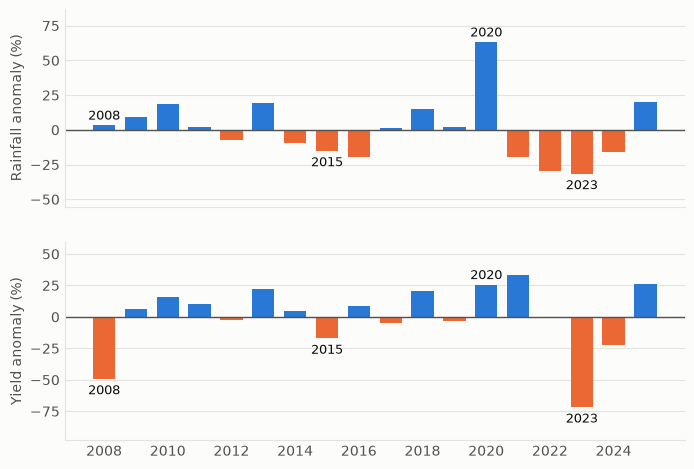

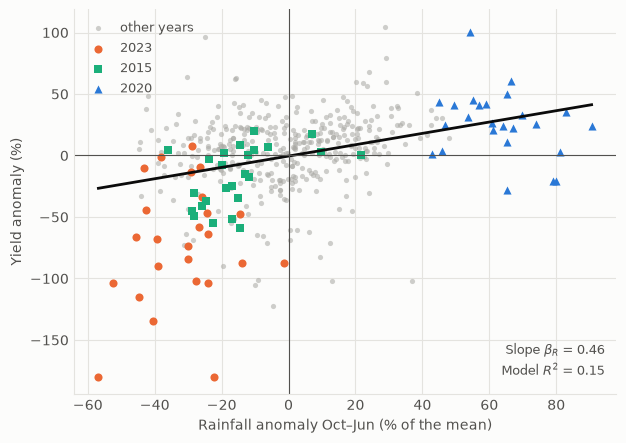

name column: NOMCOMAR | matches: 41


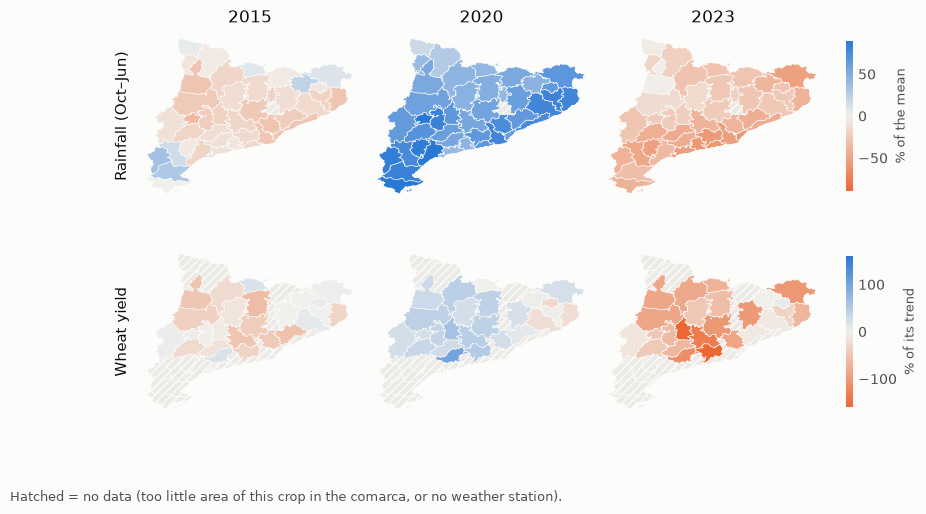

In [8]:

importlib.reload(P)

P.fig_time(data, "Blat")
P.fig_scatter(data, "Blat", highlight=(2023, 2015, 2020))
geo = P.load_comarques("../data/raw/divisions-administratives-v2r1-comarques-250000-20250730.json",fix_comarca, known=set(h.comarca))
P.fig_maps(geo, data, cm, years=(2015, 2020, 2023), crop="Blat")

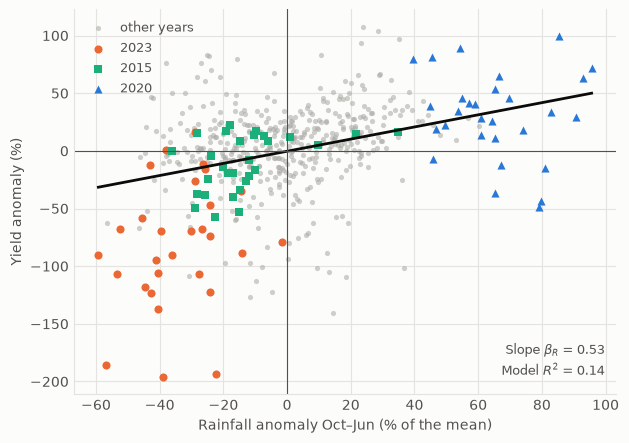

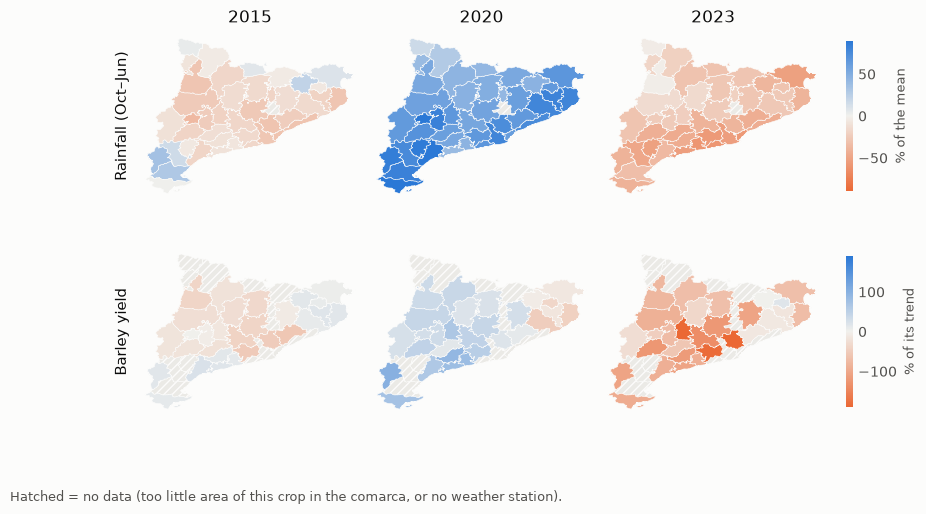

In [9]:
P.fig_scatter(data, "Ordi",highlight=(2023, 2015, 2020))
P.fig_maps(geo, data, cm, years=(2015, 2020, 2023), crop="Ordi")


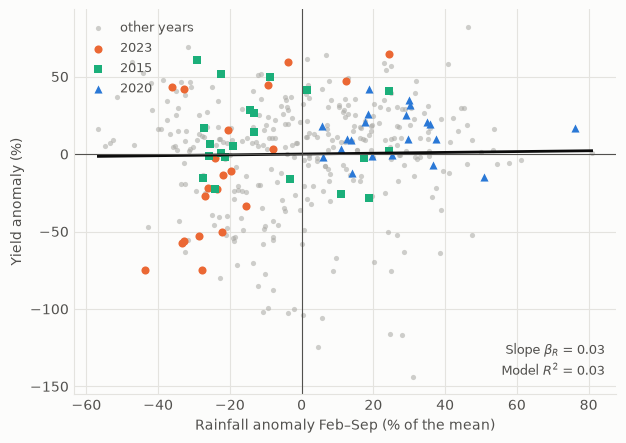

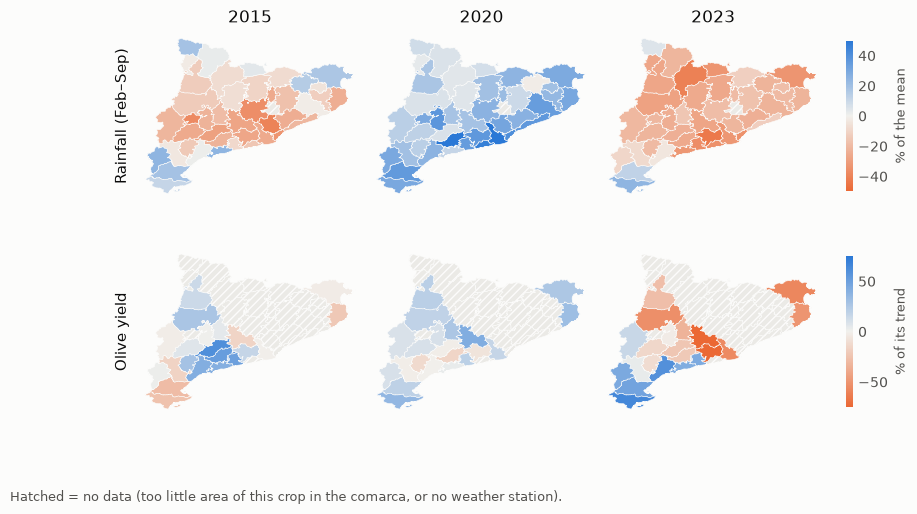

In [10]:
P.fig_scatter(data, "Olivera",highlight=(2023, 2015, 2020))
P.fig_maps(geo, data, cm, years=(2015, 2020, 2023), crop="Olivera")

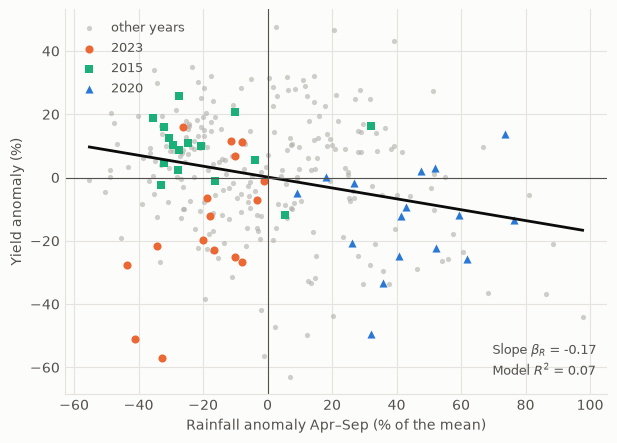

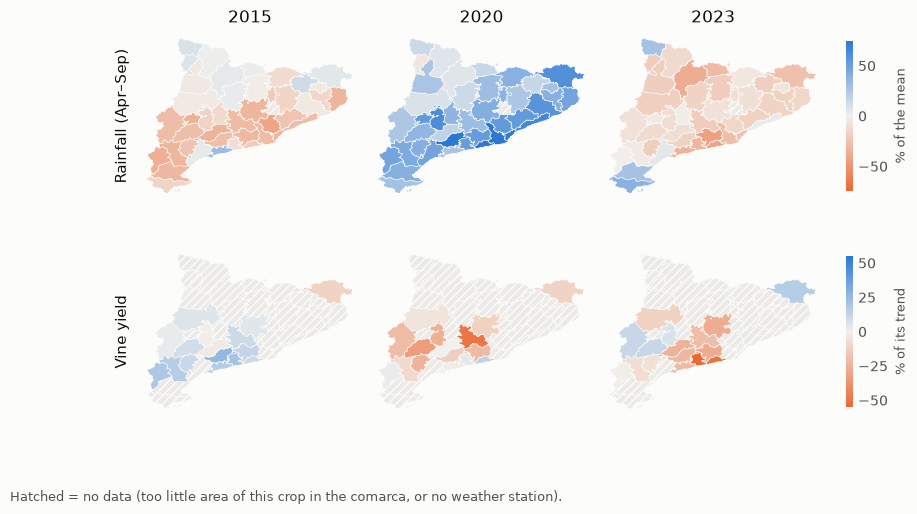

In [11]:
P.fig_scatter(data, "Vinya de raïm per a vi",highlight=(2023, 2015, 2020))
P.fig_maps(geo, data, cm, years=(2015, 2020, 2023), crop="Vinya de raïm per a vi")

### In order to condense the information, we'll convert the plots into pannels

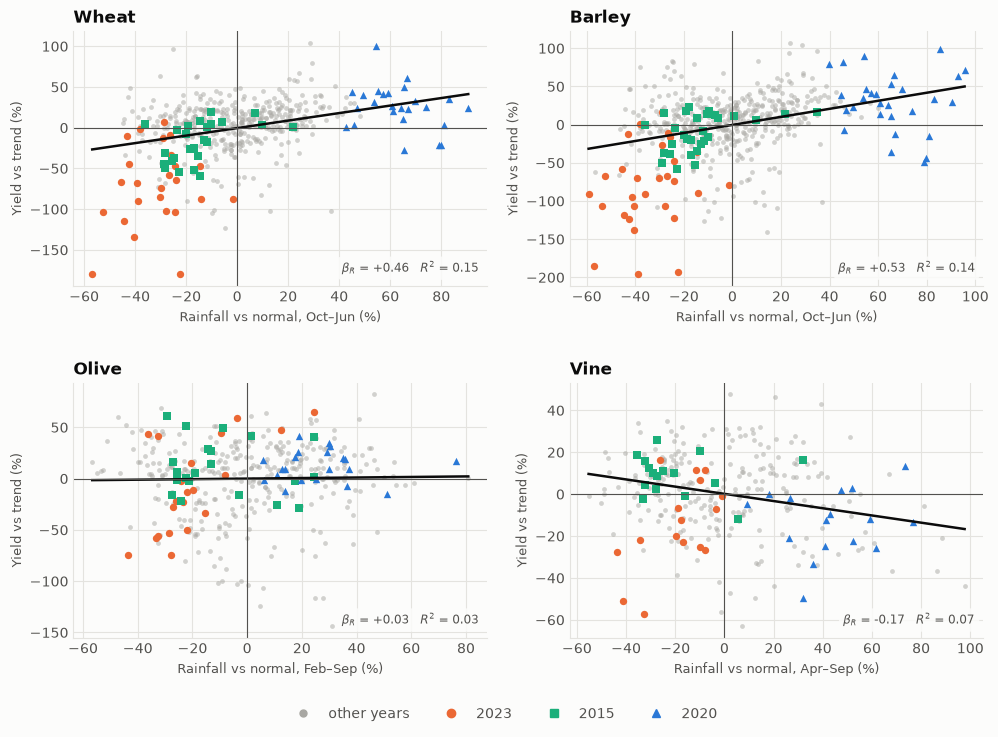

Blat                     window cereal   n = 450  (25 comarques)
  b_T =   -9.4 % per degC       [-26.8, +7.9]  p = 0.288
  b_P =  +46.1 % per +100 % rain  [+10.8, +81.4]  p = 0.010
  R2  = 0.15
Ordi                     window cereal   n = 521  (29 comarques)
  b_T =   -8.3 % per degC       [-30.4, +13.8]  p = 0.461
  b_P =  +52.7 % per +100 % rain  [+12.8, +92.5]  p = 0.010
  R2  = 0.14
Blat de moro             window growing  n = 177  (10 comarques)
  b_T =   -3.2 % per degC       [-10.9, +4.5]  p = 0.414
  b_P =  +15.2 % per +100 % rain  [+5.0, +25.4]  p = 0.004
  R2  = 0.10
Ametller                 window tree     n = 270  (15 comarques)
  b_T =   +1.2 % per degC       [-26.1, +28.5]  p = 0.931
  b_P =   +2.8 % per +100 % rain  [-28.3, +33.9]  p = 0.862
  R2  = 0.00
Olivera                  window tree     n = 378  (21 comarques)
  b_T =  -10.3 % per degC       [-36.1, +15.4]  p = 0.432
  b_P =   +2.7 % per +100 % rain  [-40.7, +46.0]  p = 0.904
  R2  = 0.03
Vinya de raïm per a vi 

In [12]:
importlib.reload(P)
importlib.reload(C)
P.fig_scatter_panel(data, crops=("Blat", "Ordi", "Olivera", "Vinya de raïm per a vi"), save="../figures/Hug/scatter_panel.png")
tab, data = C.fit(ya, cm)                    # prints
tab, data = C.fit(ya, cm, verbose=False)     # silent

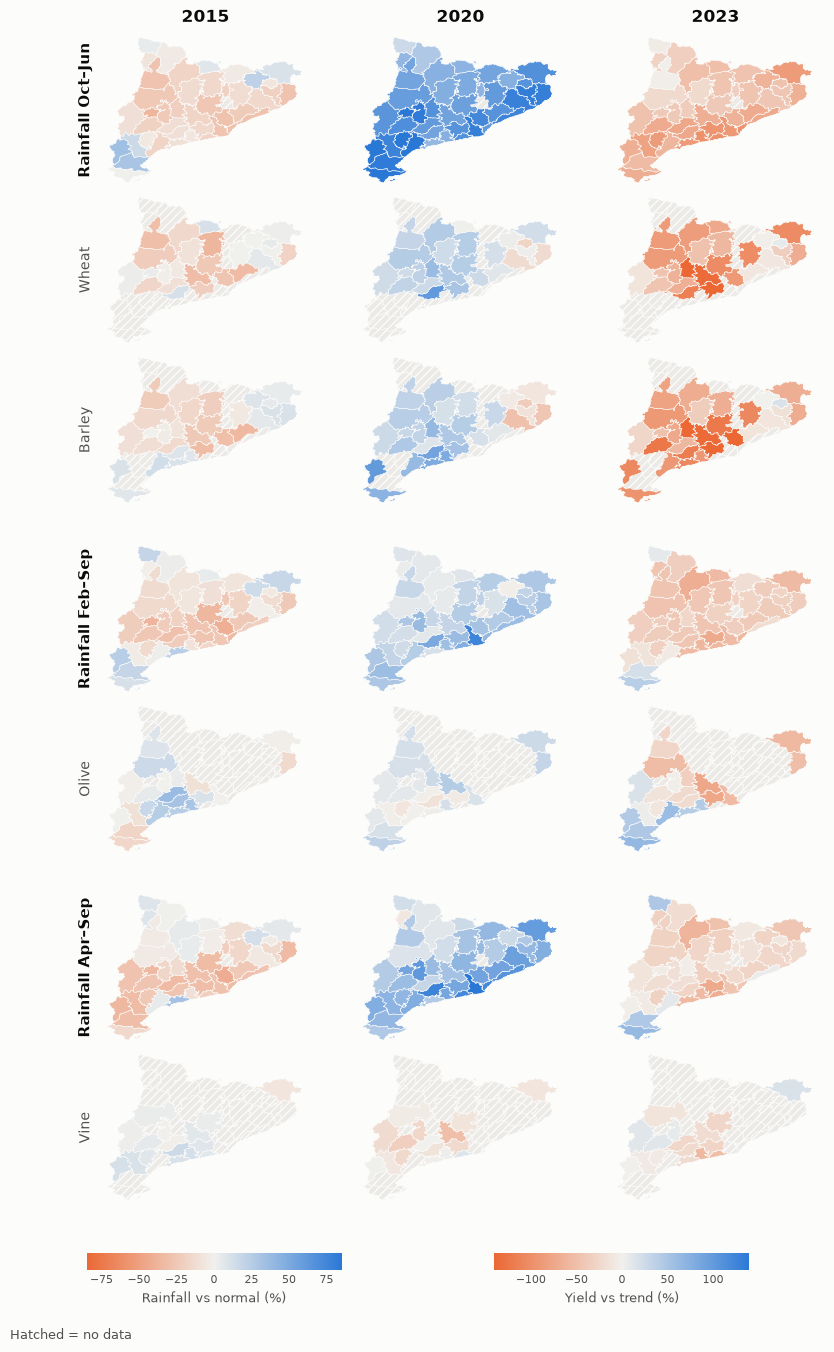

In [13]:
importlib.reload(P)
P.fig_maps_panel(geo, data, cm, years=(2015, 2020, 2023), crops=("Blat", "Ordi", "Olivera", "Vinya de raïm per a vi"), save="../figures/Hug/maps_panel.png")

### Alternative:
We've been suggested to work with a heatmap instead. Even though in the heatmap all the squares are relevant and we have a color gradient to further inform, while in the scatter plot we are focussing on specefic years therefore accumulating a lot of noise; i believe the second option is more quantitative. 

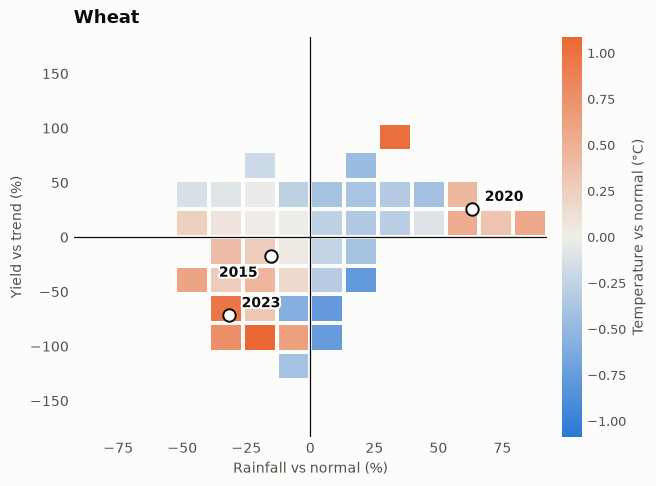

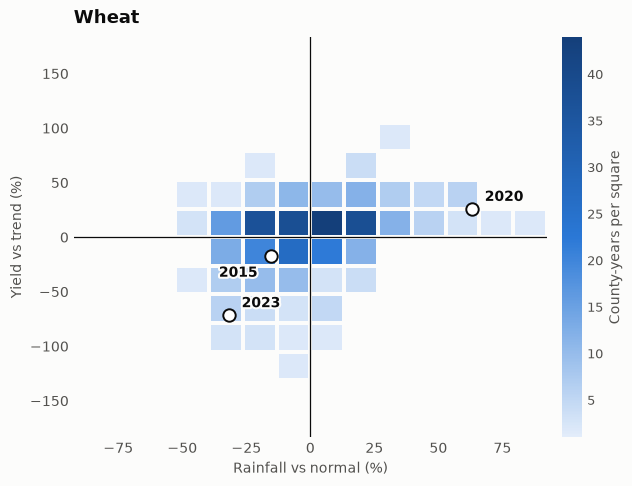

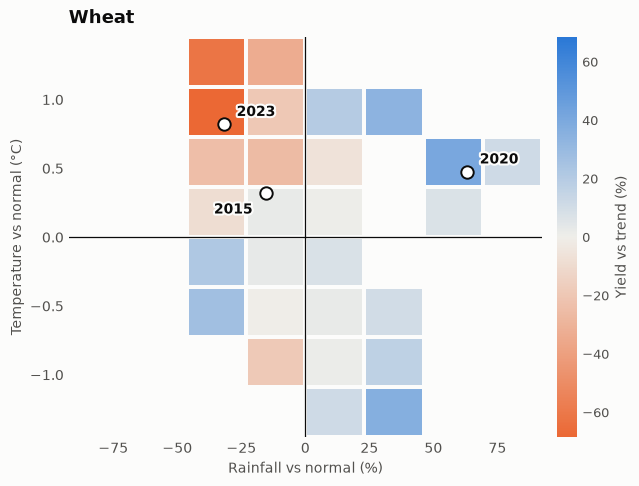

In [14]:
importlib.reload(P)
P.fig_scatter_grid(data, "Blat")                  # yield vs rain, colour = temperature
P.fig_scatter_grid(data, "Blat", color="count")   # colour = number of county-years
P.fig_quadrants(data, "Blat")